# ПР №1 — Первый notebook (уровень B)

**Задача:** прочитать табличные данные, изучить структуру, графики и сделать выводы.

**Выбор окружения:** `venv` — входит в Python и изолирует зависимости проекта без дополнительных менеджеров. Используется **Iris** — аналог разрешённого учебного датасета `tips`, потому что файл `tips` преподаватель не приложил.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

DATA = Path('../data/iris.csv')
FIG = Path('../figures'); FIG.mkdir(exist_ok=True)
df = pd.read_csv(DATA)
print('Размер таблицы:', df.shape)
print('Типы признаков:')
print(df.dtypes.to_string())
print('Пропуски по столбцам:')
print(df.isna().sum().to_string())
display(df.head())
display(df.describe(include='all'))

Размер таблицы: (150, 5)
Типы признаков:
sepal_length_cm    float64
sepal_width_cm     float64
petal_length_cm    float64
petal_width_cm     float64
species             object
Пропуски по столбцам:
sepal_length_cm    0
sepal_width_cm     0
petal_length_cm    0
petal_width_cm     0
species            0


,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm,species
count,150.000000,150.000000,150.000000,150.000000,150
unique,NaN,NaN,NaN,NaN,3
top,NaN,NaN,NaN,NaN,setosa
freq,NaN,NaN,NaN,NaN,50
mean,5.843333,3.057333,3.758000,1.199333,NaN
std,0.828066,0.435866,1.765298,0.762238,NaN
min,4.300000,2.000000,1.000000,0.100000,NaN
25%,5.100000,2.800000,1.600000,0.300000,NaN
50%,5.800000,3.000000,4.350000,1.300000,NaN
75%,6.400000,3.300000,5.100000,1.800000,NaN


## График 1 — распределение числового признака

Длина лепестка удобна для сравнения видов: её диапазон и форма распределения показывают различия цветов.

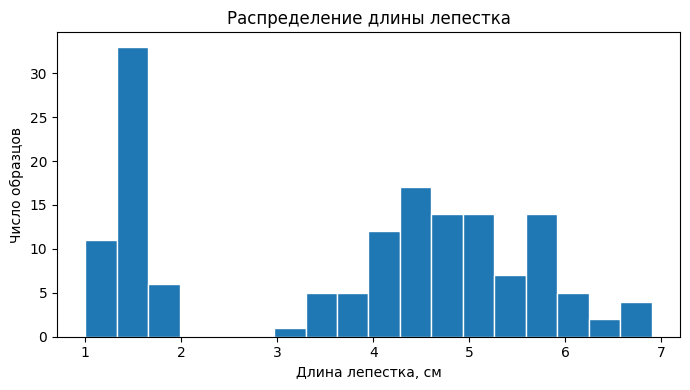

In [2]:
fig, ax = plt.subplots(figsize=(7,4))
ax.hist(df['petal_length_cm'], bins=18, edgecolor='white')
ax.set(title='Распределение длины лепестка',xlabel='Длина лепестка, см',ylabel='Число образцов')
fig.tight_layout(); fig.savefig(FIG/'petal_length_hist.png', dpi=130)
plt.show()

## График 2 — соотношение категорий

Частоты классов помогают проверить, нет ли сильного перекоса выборки.

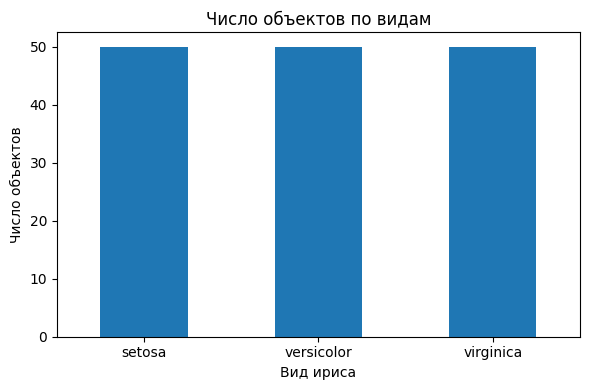

species
setosa        50
versicolor    50
virginica     50


In [3]:
counts = df['species'].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(6,4))
counts.plot(kind='bar',ax=ax,rot=0)
ax.set(title='Число объектов по видам',xlabel='Вид ириса',ylabel='Число объектов')
fig.tight_layout(); fig.savefig(FIG/'species_count.png', dpi=130)
plt.show()
print(counts.to_string())

## График 3 — связь двух размеров

Это дополнительный способ проверить, насколько признаки разделяют виды.

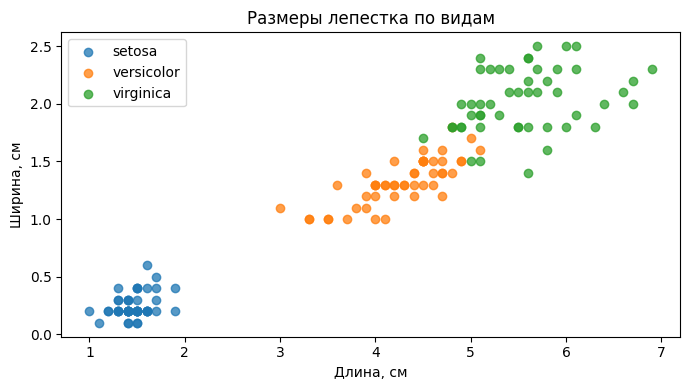

In [4]:
fig,ax=plt.subplots(figsize=(7,4))
for species,part in df.groupby('species'):
    ax.scatter(part['petal_length_cm'],part['petal_width_cm'],label=species,alpha=.75)
ax.set(title='Размеры лепестка по видам',xlabel='Длина, см',ylabel='Ширина, см')
ax.legend();fig.tight_layout();fig.savefig(FIG/'petal_scatter.png',dpi=130)
plt.show()

## Три наблюдения

1. В наборе **одинаковое число цветков каждого вида**, поэтому дисбаланса категорий нет (смотри второй график).
2. На диаграмме рассеяния **setosa образует отдельную компактную группу** по размерам лепестков, а versicolor и virginica заметно ближе друг к другу.
3. Распределение длины лепестка **не похоже на один симметричный пик**: наблюдаются группы значений, связанные с видами, поэтому усреднение по всем видам может скрывать структуру.